<a href="https://colab.research.google.com/github/divyayalam/Camouflage/blob/rishikesh-track2/track2_predictionAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

In [3]:
model = keras.models.load_model(
    "/content/drive/MyDrive/best_animal_cnn.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [15]:
(_, _), (test_images_full, test_labels_full) = \
    keras.datasets.cifar10.load_data()

In [5]:
ANIMAL_CLASS_IDS = [2, 3, 4, 5, 6, 7]

ANIMAL_NAMES = [
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse"
]

labels = test_labels_full.flatten()

mask = np.isin(labels, ANIMAL_CLASS_IDS)

test_images = test_images_full[mask]
old_labels = labels[mask]

label_map = {
    2: 0,
    3: 1,
    4: 2,
    5: 3,
    6: 4,
    7: 5
}

test_labels = np.array([
    label_map[label] for label in old_labels
])

print(test_images.shape)
print(test_labels.shape)

(6000, 32, 32, 3)
(6000,)


In [6]:
test_images_norm = test_images.astype("float32") / 255.0

print("Normalization complete")

Normalization complete


In [7]:
predictions_prob = model.predict(
    test_images_norm,
    verbose=1
)

predicted_labels = np.argmax(
    predictions_prob,
    axis=1
)

print("Predictions complete!")

188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step
Predictions complete!


In [16]:
np.savez_compressed(
    "/content/drive/MyDrive/track2_results.npz",
    predictions_prob=predictions_prob,
    predicted_labels=predicted_labels,
    test_labels=test_labels,
    test_images=test_images
)

print("Track 2 results saved to Drive!")

Track 2 results saved to Drive!


In [17]:
accuracy = np.mean(predicted_labels == test_labels)

print(f"Test accuracy: {accuracy * 100:.2f}%")

Test accuracy: 71.10%


In [18]:
correct_indices = np.where(
    predicted_labels == test_labels
)[0][:5]

incorrect_indices = np.where(
    predicted_labels != test_labels
)[0][:5]

print("Correct indices:", correct_indices)
print("Incorrect indices:", incorrect_indices)

Correct indices: [0 1 2 3 4]
Incorrect indices: [ 5 12 18 19 20]


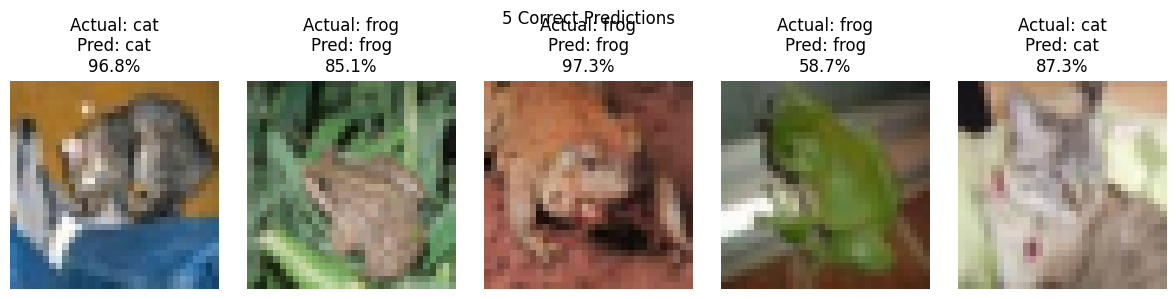

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, idx in enumerate(correct_indices):
    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[test_labels[idx]]
    predicted = ANIMAL_NAMES[predicted_labels[idx]]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Correct Predictions")
plt.tight_layout()
plt.show()

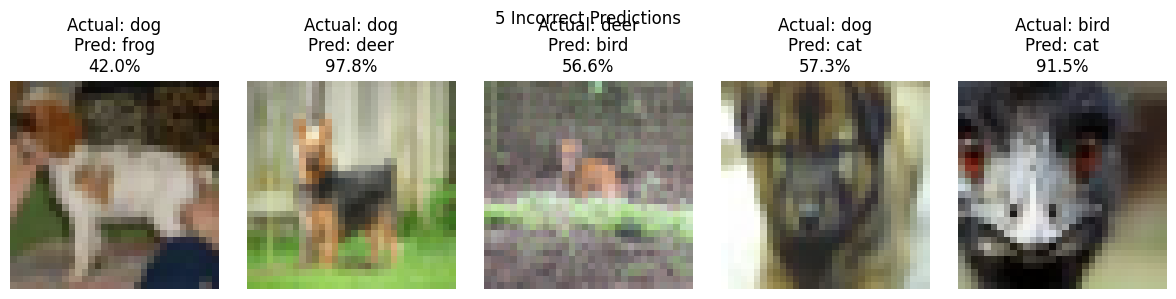

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, idx in enumerate(incorrect_indices):
    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[test_labels[idx]]
    predicted = ANIMAL_NAMES[predicted_labels[idx]]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Incorrect Predictions")
plt.tight_layout()
plt.show()

Observation:
The model performs well on many clear images, but the incorrect predictions show that it can become confused by low-resolution images, unusual poses, backgrounds, and visually similar textures. Some mistakes have relatively low confidence, suggesting uncertainty, while others are made with very high confidence. For example, a dog was classified as a deer with 97.8% confidence and a bird was classified as a cat with 91.5% confidence. These high-confidence errors suggest that the CNN may sometimes rely on misleading visual features rather than the true object itself.


In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    predicted_labels
)

print(cm)

[[675  39  48  22 126  90]
 [ 58 623  46  71 119  83]
 [ 56  47 666   1 138  92]
 [ 42 159  47 484 106 162]
 [ 34  36   5   2 913  10]
 [ 15  19  32   5  24 905]]


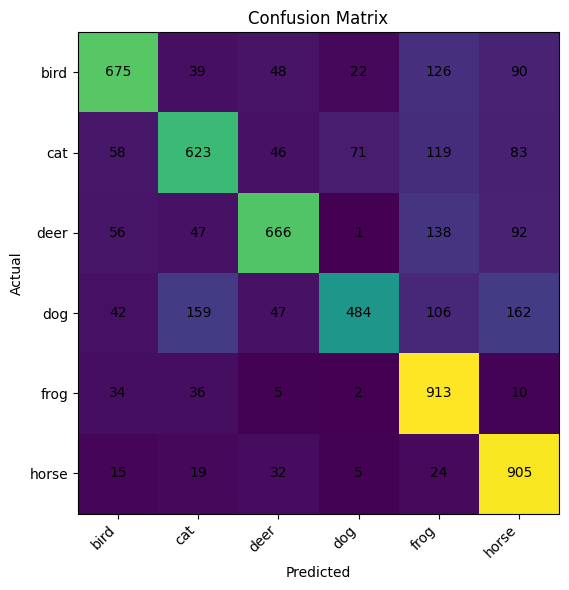

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm)

ax.set_xticks(np.arange(len(ANIMAL_NAMES)))
ax.set_yticks(np.arange(len(ANIMAL_NAMES)))

ax.set_xticklabels(ANIMAL_NAMES)
ax.set_yticklabels(ANIMAL_NAMES)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        predicted_labels,
        target_names=ANIMAL_NAMES
    )
)

              precision    recall  f1-score   support

        bird       0.77      0.68      0.72      1000
         cat       0.67      0.62      0.65      1000
        deer       0.79      0.67      0.72      1000
         dog       0.83      0.48      0.61      1000
        frog       0.64      0.91      0.75      1000
       horse       0.67      0.91      0.77      1000

    accuracy                           0.71      6000
   macro avg       0.73      0.71      0.70      6000
weighted avg       0.73      0.71      0.70      6000



In [ ]:
accuracy = np.mean(predicted_labels == test_labels)

print(f"Test accuracy: {accuracy * 100:.2f}%")

In [ ]:
correct_indices = np.where(
    predicted_labels == test_labels
)[0][:5]

incorrect_indices = np.where(
    predicted_labels != test_labels
)[0][:5]

print("Correct indices:", correct_indices)
print("Incorrect indices:", incorrect_indices)

In [ ]:
fig, axes = plt.subplots(
    1,
    5,
    figsize=(12, 3)
)

for i, idx in enumerate(correct_indices):

    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[
        test_labels[idx]
    ]

    predicted = ANIMAL_NAMES[
        predicted_labels[idx]
    ]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Correct Predictions")
plt.tight_layout()
plt.show()

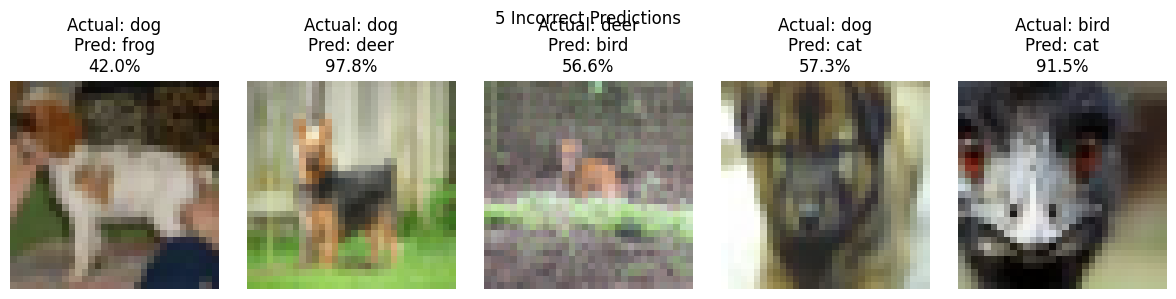

In [11]:
fig, axes = plt.subplots(
    1,
    5,
    figsize=(12, 3)
)

for i, idx in enumerate(incorrect_indices):

    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[
        test_labels[idx]
    ]

    predicted = ANIMAL_NAMES[
        predicted_labels[idx]
    ]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Incorrect Predictions")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    predicted_labels
)

print(cm)

[[675  39  48  22 126  90]
 [ 58 623  46  71 119  83]
 [ 56  47 666   1 138  92]
 [ 42 159  47 484 106 162]
 [ 34  36   5   2 913  10]
 [ 15  19  32   5  24 905]]


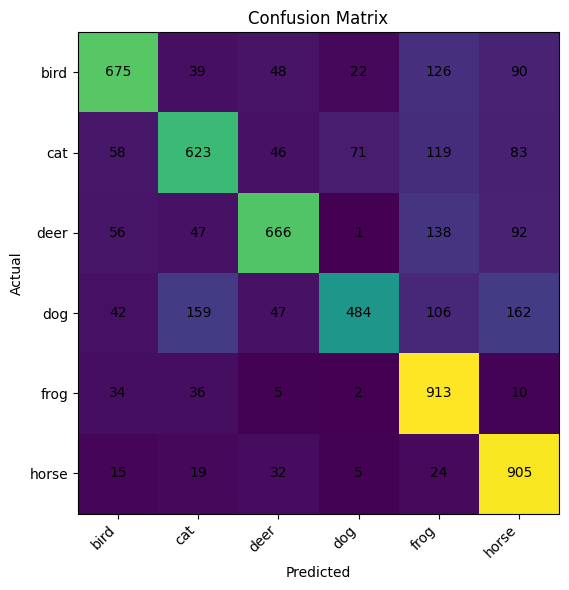

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(len(ANIMAL_NAMES))
)

ax.set_yticks(
    np.arange(len(ANIMAL_NAMES))
)

ax.set_xticklabels(
    ANIMAL_NAMES
)

ax.set_yticklabels(
    ANIMAL_NAMES
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        predicted_labels,
        target_names=ANIMAL_NAMES
    )
)

              precision    recall  f1-score   support

        bird       0.77      0.68      0.72      1000
         cat       0.67      0.62      0.65      1000
        deer       0.79      0.67      0.72      1000
         dog       0.83      0.48      0.61      1000
        frog       0.64      0.91      0.75      1000
       horse       0.67      0.91      0.77      1000

    accuracy                           0.71      6000
   macro avg       0.73      0.71      0.70      6000
weighted avg       0.73      0.71      0.70      6000

